<a href="https://colab.research.google.com/github/NEU0127/ZSUProjekt/blob/main/ZSUProjektPart1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projekt ZSU: Analýza olympijských sportovců

Tento Jupyter Notebook obsahuje průzkumnou analýzu (EDA), preprocessing dat a shlukovou analýzu nad datasetem olympijských sportovců. Postupně projdeme vizualizace distribucí, vztahy mezi proměnnými, obhájíme čištění dat a vyhodnotíme optimální rozdělení sportovců do shluků pomocí dvou odlišných algoritmů.

* **použitý dataset:** Olympijští sportovci (https://www.kaggle.com/datasets/heesoo37/120-years-of-olympic-history-athletes-and-results)

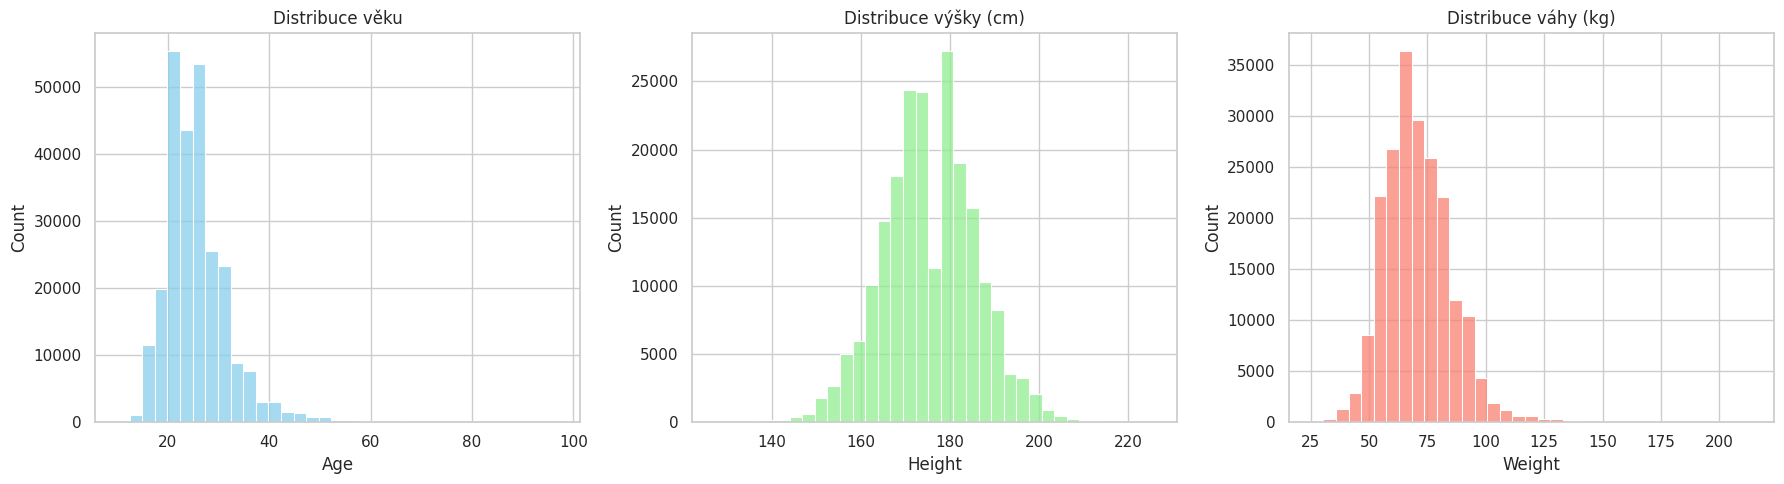

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

df_olympics = pd.read_csv('athlete_events.csv')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(data=df_olympics, x='Age', bins=35, ax=axes[0], color='skyblue')
axes[0].set_title('Distribuce věku')
sns.histplot(data=df_olympics, x='Height', bins=35, ax=axes[1], color='lightgreen')
axes[1].set_title('Distribuce výšky (cm)')
sns.histplot(data=df_olympics, x='Weight', bins=35, ax=axes[2], color='salmon')
axes[2].set_title('Distribuce váhy (kg)')
plt.tight_layout()
plt.show()

### Interpretace univariantní analýzy
* **Věk (Age):** Distribuce věku je silně zešikmená doprava a vrcholí u hodnot těsně nad 20 lety. Pravý chvost grafu však sahá až k hodnotám blížícím se 100 letům, což ukazuje na účast starších sportovců v některých disciplínách.
* **Výška (Height):** Rozdělení výšky připomíná normální distribuci, přičemž absolutní většina hodnot se pohybuje zhruba mezi 160 a 190 cm. Extrémní hodnoty na osách pokrývají spektrum od zhruba 140 cm až k 220 cm.
* **Váha (Weight):** Distribuce váhy je rovněž zešikmená doprava s výrazným vrcholem kolem 60 až 75 kg. Existuje zde dlouhý pravý chvost záznamů, které přesahují 150 kg a blíží se až k hranici 200 kg.

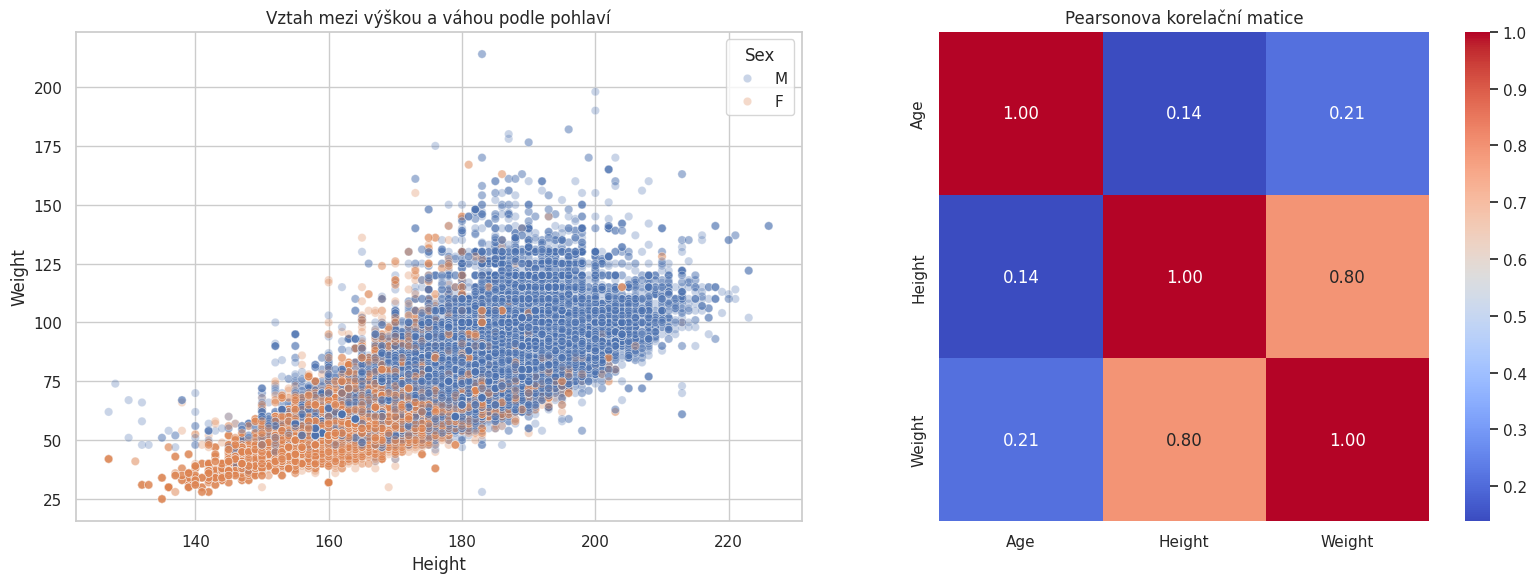

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(data=df_olympics, x='Height', y='Weight', hue='Sex', alpha=0.3, ax=axes[0])
axes[0].set_title('Vztah mezi výškou a váhou podle pohlaví')

numeric_cols = ['Age', 'Height', 'Weight']
corr_matrix = df_olympics[numeric_cols].corr(method='pearson')
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", square=True, ax=axes[1])
axes[1].set_title('Pearsonova korelační matice')

plt.tight_layout()
plt.show()

### Interpretace bivariantní analýzy a korelací
* **Výška vs. Váha:** Bodový graf ukazuje silnou pozitivní závislost mezi výškou a váhou sportovců. Podle barevného rozlišení tvoří muži (M, modrá barva) převážně horní pravou část spektra s vyšší váhou i výškou, zatímco ženy (F, oranžová barva) se nacházejí spíše v levé dolní části grafu.

* **Korelační matice:** Výsledky matice potvrzují zjištění z bodového grafu, jelikož Pearsonův korelační koeficient mezi výškou a váhou dosahuje velmi vysoké hodnoty 0.80. Korelace věku s tělesnými rozměry je naopak velmi nízká, konkrétně 0.14 pro výšku a 0.21 pro váhu.

In [46]:
df_olympics['Height'] = df_olympics.groupby(['Sport', 'Sex'])['Height'].transform(lambda x: x.fillna(x.median()))
df_olympics['Weight'] = df_olympics.groupby(['Sport', 'Sex'])['Weight'].transform(lambda x: x.fillna(x.median()))

df_olympics['Height'] = df_olympics['Height'].fillna(df_olympics['Height'].median())
df_olympics['Weight'] = df_olympics['Weight'].fillna(df_olympics['Weight'].median())
df_olympics['Age'] = df_olympics['Age'].fillna(df_olympics['Age'].median())

df_olympics['Medal'] = df_olympics['Medal'].fillna('None')

df_olympics['BMI'] = df_olympics['Weight'] / ((df_olympics['Height'] / 100) ** 2)
df_olympics['Medal_Won'] = df_olympics['Medal'].apply(lambda x: 0 if x == 'None' else 1)
df_olympics['Age_Group'] = pd.cut(df_olympics['Age'], bins=[10, 20, 30, 40, 100], labels=['Teens', '20s', '30s', '40+'])

print("Ukázka datasetu")
display(df_olympics[['Name', 'Sex', 'Sport', 'Height', 'Weight', 'BMI', 'Age_Group', 'Medal_Won']].head())

Ukázka datasetu


,Name,Sex,Sport,Height,Weight,BMI,Age_Group,Medal_Won
0,A Dijiang,M,Basketball,180.0,80.0,24.691358,20s,0
1,A Lamusi,M,Judo,170.0,60.0,20.761246,20s,0
2,Gunnar Nielsen Aaby,M,Football,178.0,73.0,23.040020,20s,0
3,Edgar Lindenau Aabye,M,Tug-Of-War,182.0,95.0,28.680111,30s,1
4,Christine Jacoba Aaftink,F,Speed Skating,185.0,82.0,23.959094,20s,0


### Odůvodnění čištění dat a tvorby nových proměnných
* **Chybějící hodnoty:** Nahradit chybějící výšku nebo váhu prostým globálním průměrem by smazalo fyziologické rozdíly. Využili jsme transformaci přes `groupby`, která hodnoty imputovala pomocí mediánu specifického pro daný **sport a pohlaví** (např. chybějící váha basketbalisty se odvodí z mediánu ostatních basketbalistů, nikoliv gymnastek).
* **Feature Engineering:** Vytvořili jsme odvozené proměnné z logiky domény.
  1. `BMI` (Body Mass Index) lépe vystihuje fyziologický profil sportovce a poslouží lépe pro shlukování než surová výška/váha.
  2. `Medal_Won` převádí textovou proměnnou na binární ukazatel úspěchu.
  3. `Age_Group` kategorizuje spojitý věk do biologicky relevantních dekád.

In [47]:
# Detekce odlehlých hodnot (Outliers) pomocí IQR
numeric_cols = ['Age', 'Height', 'Weight']
Q1 = df_olympics[numeric_cols].quantile(0.25)
Q3 = df_olympics[numeric_cols].quantile(0.75)
IQR = Q3 - Q1

# Identifikace extrémů mimo rozsah Q1-1.5*IQR a Q3+1.5*IQR
outliers = ((df_olympics[numeric_cols] < (Q1 - 1.5 * IQR)) | (df_olympics[numeric_cols] > (Q3 + 1.5 * IQR))).sum()

print("Počet odlehlých hodnot pro jednotlivé proměnné:")
print(outliers)

Počet odlehlých hodnot pro jednotlivé proměnné:
Age       11981
Height     3024
Weight     5357
dtype: int64


### Strategie pro řešení odlehlých hodnot (Outliers)
Výpočet IQR odhalil tisíce odlehlých hodnot, především u váhy a věku. **Rozhodli jsme se tyto hodnoty záměrně zachovat a neodstraňovat je.** V doméně vrcholového sportu nepředstavují tyto extrémy chybu měření (noise), ale naopak validní fyziologické profily specifických disciplín (např. vzpěrači nad 130 kg nebo jezdci na koni nad 40 let). Jejich odstranění by model ochudilo o schopnost tyto unikátní skupiny shlukovat.

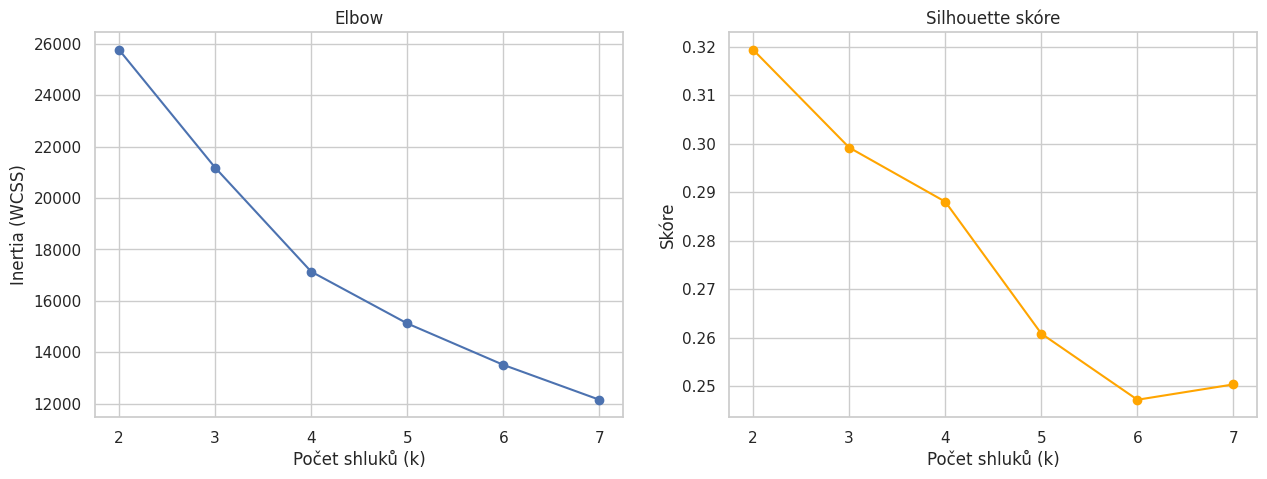

In [48]:
cluster_features = ['Age', 'Height', 'Weight', 'BMI']
X = df_olympics[cluster_features].dropna().copy()

X_sample = X.sample(n=10000, random_state=42)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_sample)

inertia = []
sil_scores = []
k_range = range(2, 8)

for k in k_range:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    inertia.append(kmeans.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(k_range, inertia, marker='o')
axes[0].set_title('Elbow')
axes[0].set_xlabel('Počet shluků (k)')
axes[0].set_ylabel('Inertia (WCSS)')

axes[1].plot(k_range, sil_scores, marker='o', color='orange')
axes[1].set_title('Silhouette skóre')
axes[1].set_xlabel('Počet shluků (k)')
axes[1].set_ylabel('Skóre')
plt.show()

### Matematické podložení počtu shluků
Graf loktové metody (Inertia) ukazuje postupné klesání hodnot vnitroshlukového rozptylu, přičemž po hodnotě k = 3 a k = 4 se pokles začíná mírně zpomalovat. Silhouette skóre dosahuje své nejvyšší hodnoty (0.32) pro k = 2. Skóre pro k = 3 je však druhou nejvyšší hodnotou (kolem 0.30) a po ní následuje strmější pád pod 0.29. Zvolili jsme 3 clustery, protože tato volba matematicky nabízí stále vysokou kvalitu separace a zároveň umožňuje detailnější fyziologickou segmentaci atletů.

In [49]:
k_optimal = 3

kmeans_final = KMeans(n_clusters=k_optimal, n_init=10, random_state=42)
X_sample['KMeans_Cluster'] = kmeans_final.fit_predict(X_scaled)

agglo = AgglomerativeClustering(n_clusters=k_optimal, linkage='ward')
X_sample['Agglo_Cluster'] = agglo.fit_predict(X_scaled)

cluster_profiles = X_sample.groupby('KMeans_Cluster')[cluster_features].mean().round(2)
cluster_profiles['Count'] = X_sample['KMeans_Cluster'].value_counts()

print("Profily shluků podle algoritmu K-Means (průměrné hodnoty):")
display(cluster_profiles)

Profily shluků podle algoritmu K-Means (průměrné hodnoty):


,Age,Height,Weight,BMI,Count
KMeans_Cluster,,,,,
0,23.99,181.58,77.10,23.38,4483
1,23.84,167.07,58.87,21.07,4035
2,34.45,179.82,85.15,26.26,1482


### Reálná interpretace výsledných shluků (K-Means)
Rozdělení datasetu na 3 shluky odhaluje základní fenotypy mezi olympioniky:

* **Shluk 0 (Vyšší atletický profil):** Nejpočetnější skupina s 4483 záznamy. Průměrný věk je 23.99 let, výška 181.58 cm a váha 77.10 kg, což odpovídá BMI 23.38. Reprezentuje klasického urostlejšího olympionika napříč mnoha sporty.
* **Shluk 1 (Drobní a lehcí sportovci):** Skupina 4035 sportovců, která se vyznačuje nejnižší průměrnou výškou (167.07 cm) a velmi nízkou vahou (58.87 kg), což generuje nejnižší BMI 21.07. Průměrný věk je 23.84 let. Reálně jde například o vytrvalostní běžce či gymnastky.
* **Shluk 2 (Starší a těžší sportovci):** Nejméně početná skupina (1482), která se výrazně odlišuje vysokým průměrným věkem 34.45 let. Tito atleti mají zároveň nejvyšší váhu (85.15 kg) a BMI (26.26) při výšce 179.82 cm. Profilově to odpovídá velmi zkušeným veteránům ve specifických silových či technických disciplínách.

In [50]:
# Doplnění informace o medailích do našeho vzorku pro shlukování
X_sample['Medal_Won'] = df_olympics.loc[X_sample.index, 'Medal_Won']

# Výpočet procentuální úspěšnosti pro každý shluk
medal_success = X_sample.groupby('KMeans_Cluster')['Medal_Won'].mean() * 100

print("Procentuální šance na zisk medaile podle fyziologického shluku:")
display(medal_success.round(2).astype(str) + ' %')

Procentuální šance na zisk medaile podle fyziologického shluku:


,Medal_Won
KMeans_Cluster,
0,15.59 %
1,11.05 %
2,16.4 %


### Interpretace vztahu shluků a úspěšnosti
Z dat jasně vyplývá, že fyziologický profil koreluje s pravděpodobností zisku medaile. Nejnižší šanci na medaili (11.05 %) mají "drobní a lehcí sportovci" tvořící shluk 1. Běžný "vyšší atletický profil" (shluk 0) je s úspěšností 15.59 % druhou nejúspěšnější skupinou. Nejvyšší medailovou úspěšnost (16.4 %) vykazuje shluk 2, tedy skupina "starší a těžší sportovci" (veteráni a siloví atleti). Tento rozdíl (více než 5 procentních bodů mezi nejlehčí a nejtěžší skupinou) naznačuje, že specifické silové a technické disciplíny mohou mít odlišnou strukturu konkurence, nebo že fyzická vyzrálost a hrubá síla hrají v celkovém měřítku olympijských her statisticky významnou roli.